# 03 · Model training and comparison
This is binary classification of (GPS point, candidate arc) pairs.
- **Training/CV:** 78 training trips (2 anomalous trips excluded), 5-fold **GroupKFold by trip**.
- **Development test:** the 10 `student_test` trips.
- **Primary metric:** observation-level Top-1 accuracy.

Each model below is trained live on the training partition and evaluated on student_test, using the same code and seed as `03_train_compare.py`.
Set `RUN_CV = True` to also re-run the 5-fold CV live; it's slow for KNN and RandomForest. Otherwise the CV numbers are loaded from the script's log `results/model_cv_folds.csv`.

In [1]:
import os, sys, json, time, warnings
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src")); sys.path.insert(0, os.path.join(ROOT, "scripts"))
os.chdir(os.path.join(ROOT, "scripts"))  # scripts use paths relative to the repo
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, IFrame, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DATA, RES, FIG = os.path.join(ROOT, "data"), os.path.join(ROOT, "results"), os.path.join(ROOT, "results", "figures")

In [2]:
import importlib
tc = importlib.import_module("03_train_compare")
from pathsnap.core import FEATURES
from pathsnap.metrics import full_eval, candidate_metrics
RUN_CV = False
c, o = tc.load_train()
ct = pd.read_parquet(f"{RES}/data/cand_student_test.parquet"); ot = pd.read_parquet(f"{RES}/data/obs_student_test.parquet")
arcs_tr, arcs_te = tc.arcs_for("train"), tc.arcs_for("student_test")
X, y = c[FEATURES].values, c["y"].values
print("training rows:", X.shape, "positive rate: %.3f" % y.mean(), "| student_test rows:", len(ct))
MODELS = tc.make_models(); logged_folds = pd.read_csv(f"{RES}/model_cv_folds.csv")
results = {}

def run(name):
    fam, cfg, make = MODELS[name]
    print(f"{name}  [{fam}]  {cfg}")
    cvr = tc.cv_eval(make, c, o, arcs_tr) if RUN_CV else logged_folds[logged_folds.model == name]
    t0 = time.time(); m = make()
    if name == "MLP": m.fit(X, y, ct[FEATURES].values, ct["y"].values)
    else: m.fit(X, y)
    fit = time.time() - t0
    t0 = time.time(); p = m.predict_proba(ct[FEATURES].values)[:, 1]; inf = time.time() - t0
    cc = ct.copy(); cc["p"] = p; met, _ = full_eval(cc, ot, arcs_te)
    row = dict(cv_macro_f1=cvr.macro_f1.mean(), cv_top1=cvr.top1_acc.mean(), test_top1=met["top1_acc"], test_macro_f1=met["macro_f1"],
               test_log_loss=met["log_loss"], test_route_continuity=met["route_continuity"], fit_s=fit, infer_ms_per_1k_obs=1e6*inf/len(ot))
    results[name] = row; display(pd.DataFrame([row]).round(4)); return m

training rows: (341205, 17) positive rate: 0.177 | student_test rows: 113639


## LogisticRegression — linear, calibrated baseline

In [3]:
m_LogisticRegression = run("LogisticRegression")

LogisticRegression  [Linear / probabilistic]  C=1.0, L2, StandardScaler


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.9107,0.8906,0.8703,0.9071,0.1399,0.7107,0.7867,0.8007


## GaussianNB — generative probabilistic model

In [4]:
m_GaussianNB = run("GaussianNB")

GaussianNB  [Probabilistic (generative)]  var_smoothing=1e-9


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.8571,0.8747,0.8636,0.8438,0.5902,0.7092,0.0865,1.205


## KNN — instance-based (slow inference)

In [5]:
m_KNN = run("KNN")

KNN  [Instance-based]  k=31, distance-weighted, StandardScaler


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.9233,0.8878,0.873,0.9196,0.1588,0.7264,0.0984,3315.0349


## RandomForest — bagging ensemble (~2 min fit)

In [6]:
m_RandomForest = run("RandomForest")

RandomForest  [Bagging ensemble]  200 trees, min_samples_leaf=5, max_features=sqrt


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.936,0.9024,0.8948,0.934,0.092,0.7531,113.5094,54.9145


## LightGBM — gradient boosting (selected)

In [7]:
m_LightGBM = run("LightGBM")

LightGBM  [Gradient boosting]  300 rounds, lr=0.05, num_leaves=31


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.938,0.9051,0.9049,0.9388,0.0874,0.756,4.181,39.782


## XGBoost — gradient boosting (depth-wise)

In [8]:
m_XGBoost = run("XGBoost")

XGBoost  [Gradient boosting]  300 rounds, lr=0.1, max_depth=6, hist


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.9368,0.9049,0.9041,0.9383,0.0876,0.7689,4.2522,12.3084


## MLP — shallow neural network, epoch-wise history

In [9]:
m_MLP = run("MLP")

MLP  [Neural network]  64-32 ReLU, Adam lr=1e-3, alpha=1e-4, 25 epochs, StandardScaler


,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
0,0.9305,0.8995,0.888,0.9285,0.1019,0.7495,22.2086,3.3966


## MLP training history (real, epoch-wise)

In [10]:
h = pd.DataFrame(m_MLP.history); plt.plot(h.epoch, h.train_loss, label="train"); plt.plot(h.epoch, h.val_loss, label="student_test"); plt.legend(); plt.xlabel("epoch"); plt.ylabel("log loss"); plt.show()

## Comparison (live run) vs. logged script results

In [11]:
live = pd.DataFrame(results).T; display(live.round(4))
logged = pd.read_csv(f"{RES}/model_comparison.csv").set_index("model")
print("max |live - logged| test Top-1:", float(np.abs(live.test_top1 - logged.loc[live.index, "test_top1"]).max()))

,cv_macro_f1,cv_top1,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_s,infer_ms_per_1k_obs
LogisticRegression,0.9107,0.8906,0.8703,0.9071,0.1399,0.7107,0.7867,0.8007
GaussianNB,0.8571,0.8747,0.8636,0.8438,0.5902,0.7092,0.0865,1.2050
KNN,0.9233,0.8878,0.8730,0.9196,0.1588,0.7264,0.0984,3315.0349
RandomForest,0.9360,0.9024,0.8948,0.9340,0.0920,0.7531,113.5094,54.9145
LightGBM,0.9380,0.9051,0.9049,0.9388,0.0874,0.7560,4.1810,39.7820
XGBoost,0.9368,0.9049,0.9041,0.9383,0.0876,0.7689,4.2522,12.3084
MLP,0.9305,0.8995,0.8880,0.9285,0.1019,0.7495,22.2086,3.3966


max |live - logged| test Top-1: 0.0


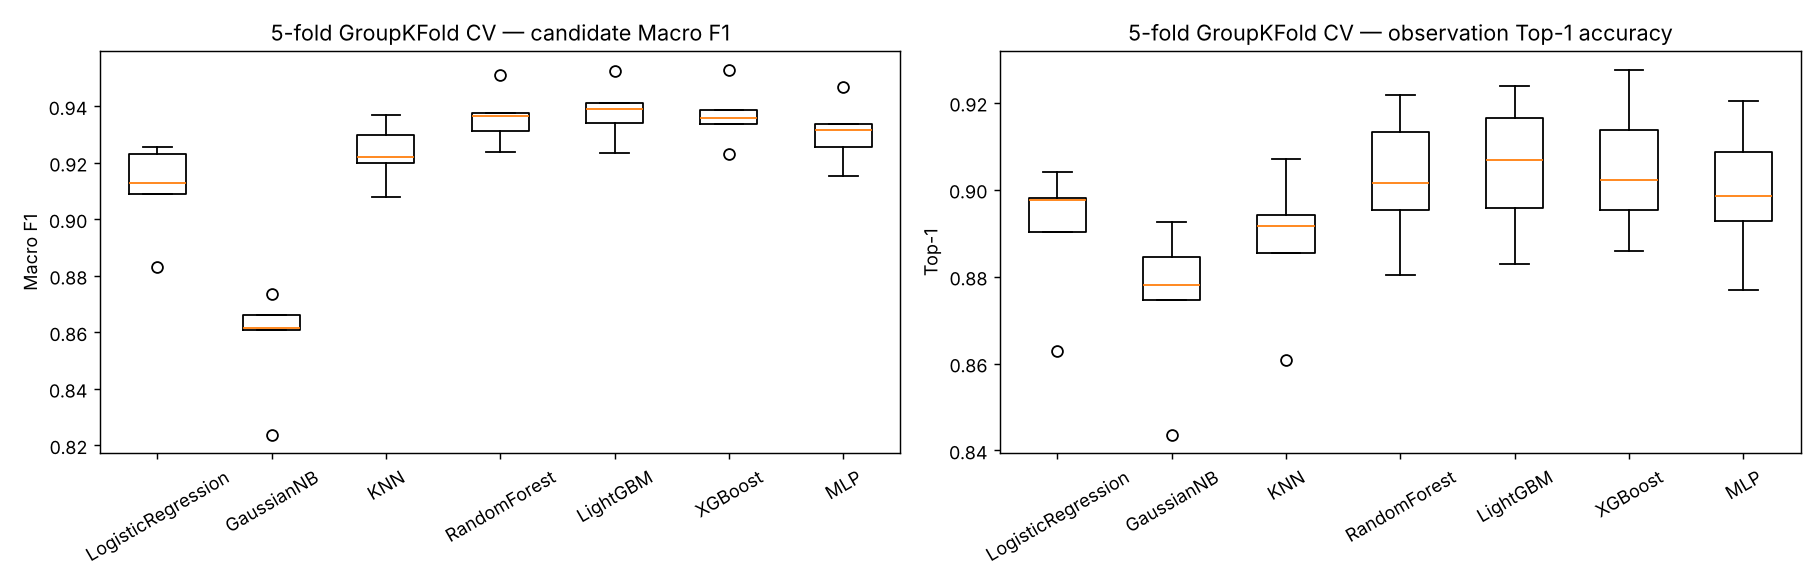

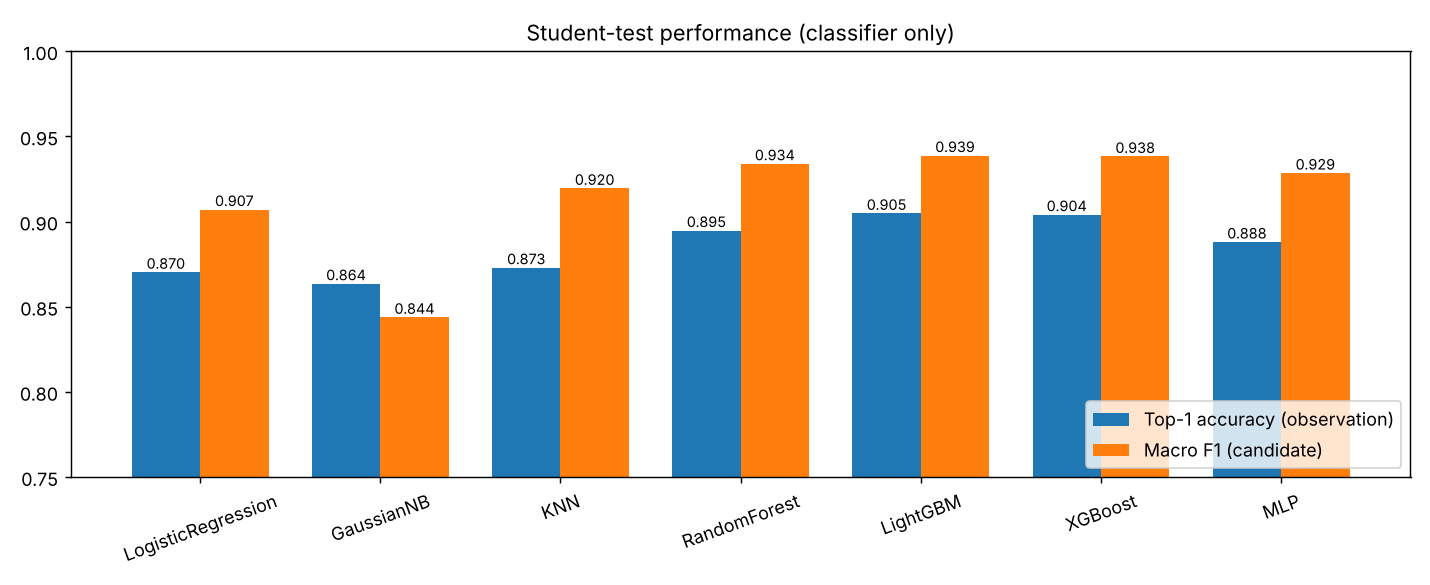

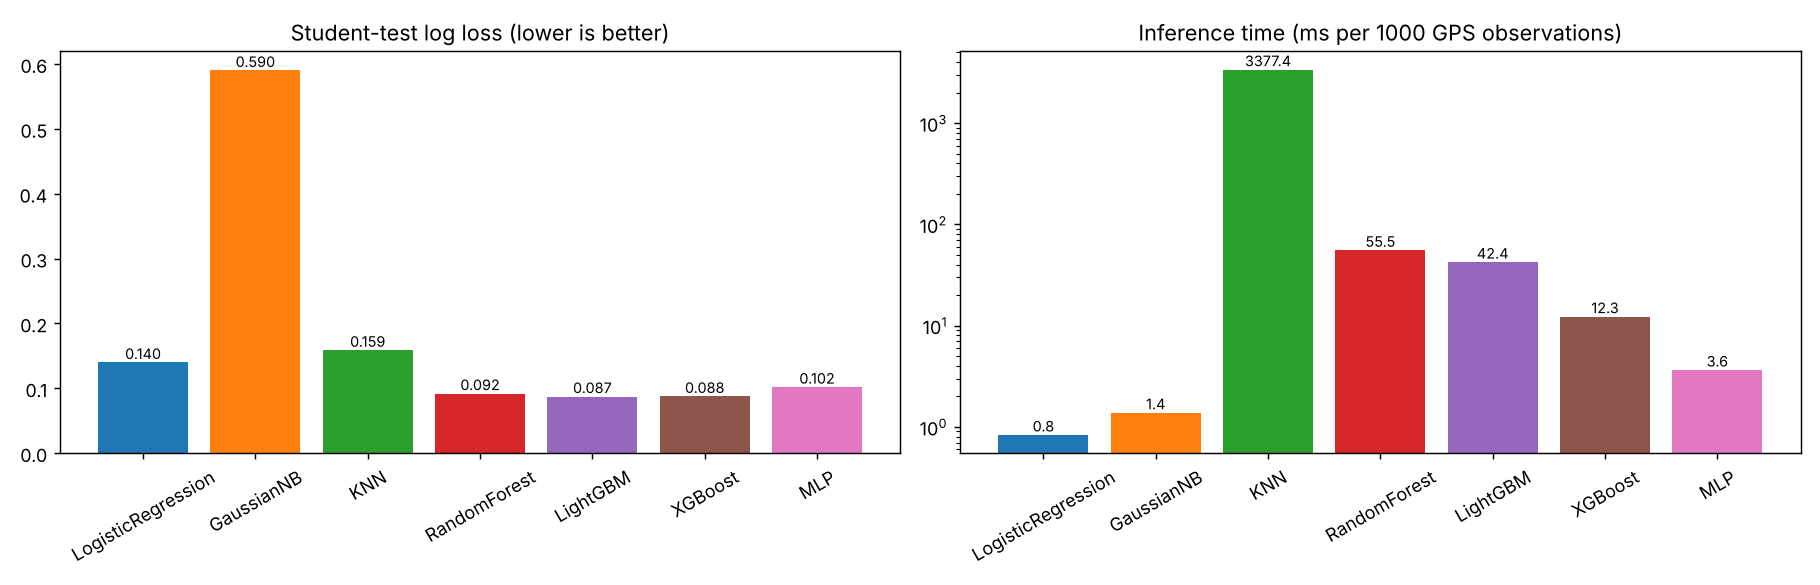

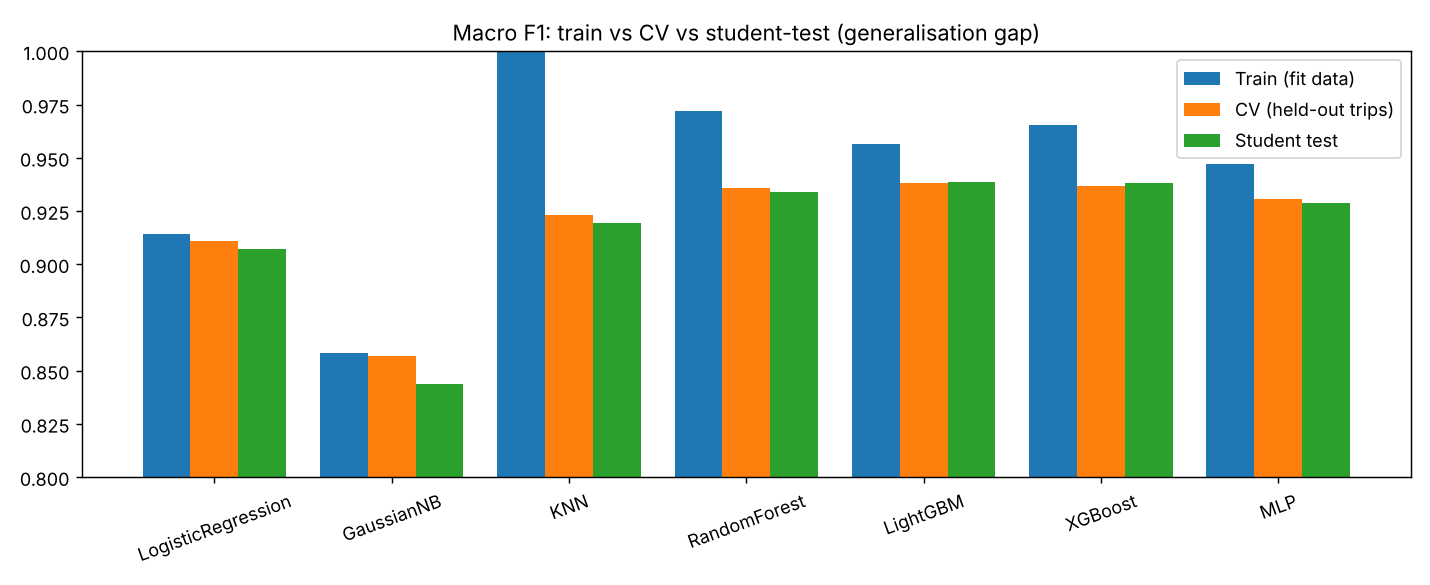

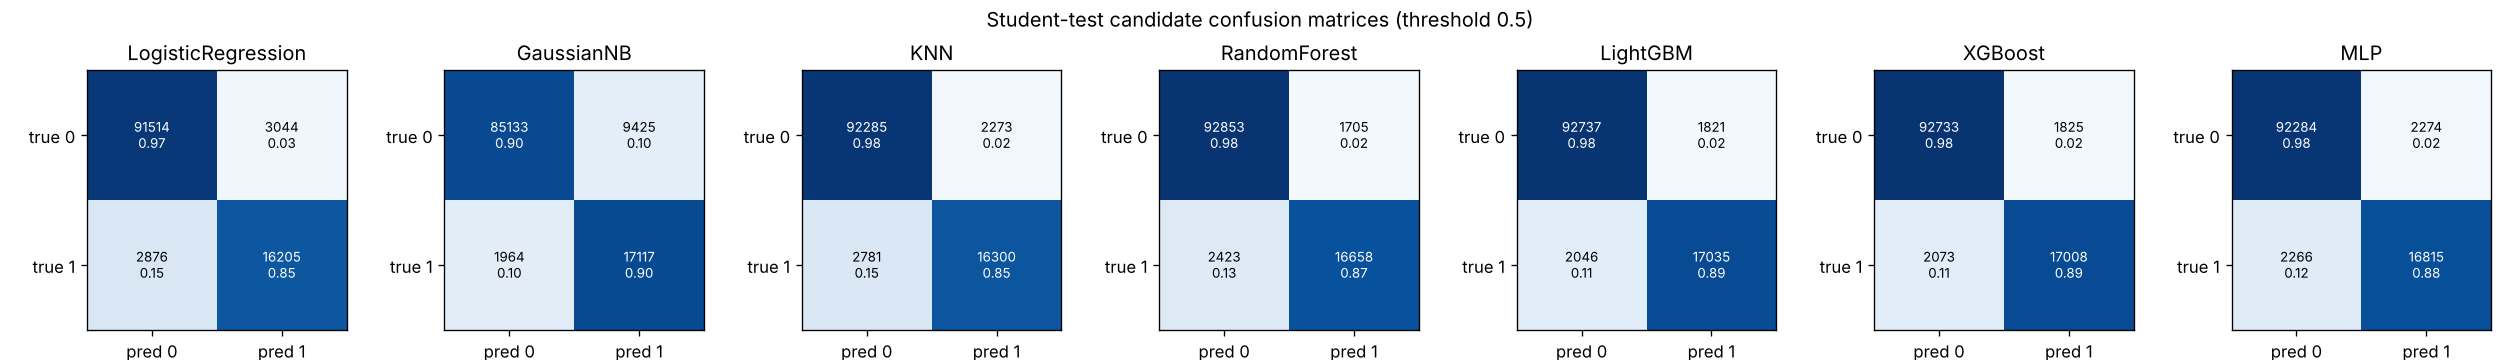

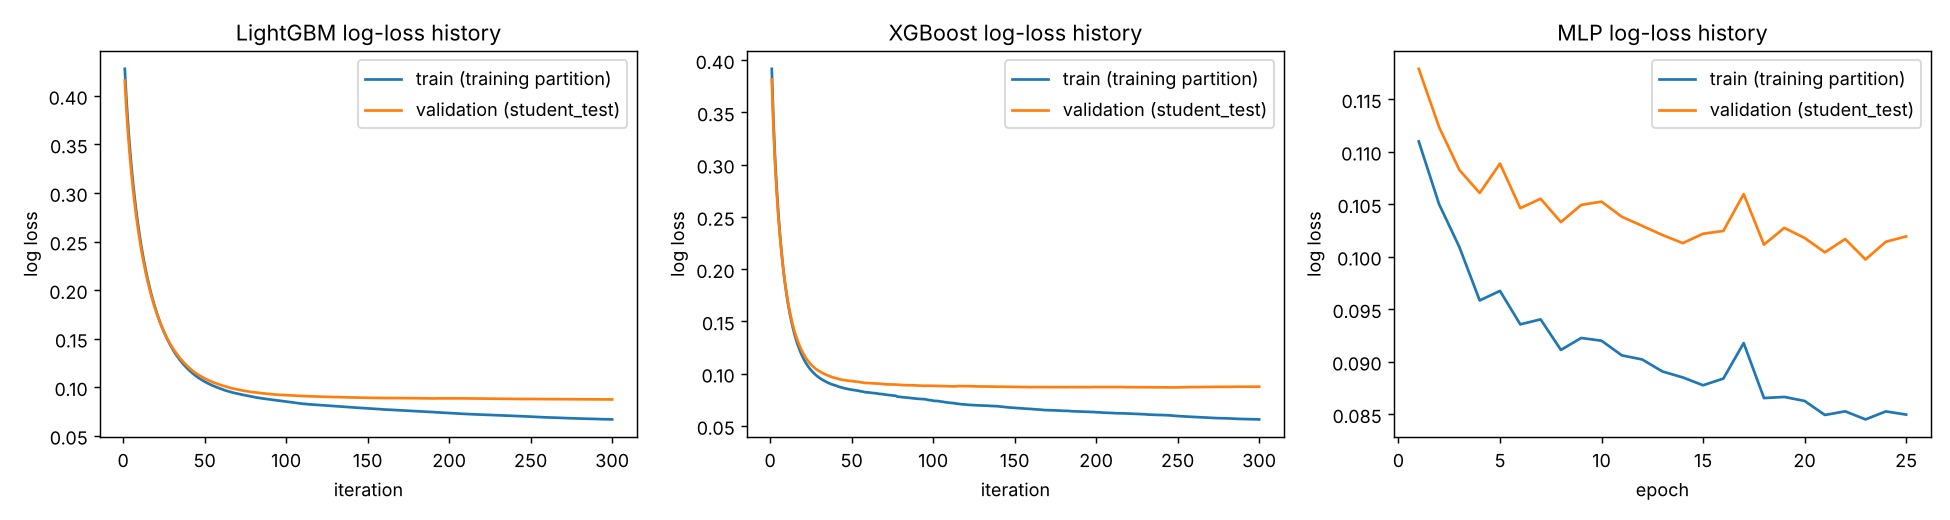

In [12]:
for f in ["cv_macro_f1_top1.png", "student_test_top1_f1.png", "logloss_inference.png", "generalisation_gap.png", "confusion_matrices.png", "training_histories.png"]:
    display(Image(f"{FIG}/{f}", width=1000))

**Selection: LightGBM.** It has the best CV Macro F1, CV Top-1 and log loss, and the best student-test Top-1/F1/log loss, with fast training and inference. XGBoost is essentially tied. KNN is too slow at inference. LogReg and GaussianNB underfit.